In [3]:
%pip install matplotlib numpy pandas seaborn scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import os

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd


import seaborn as sns

from sklearn.cluster import KMeans

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.metrics import (

    accuracy_score,

    confusion_matrix,

    mean_squared_error,

    r2_score,

)

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

 

# Sett stil på plott

sns.set_theme(style="whitegrid")

plt.rcParams.update({"font.size": 11})

 

# Lag mappe for figurer dersom den ikke finnes

os.makedirs("figurer", exist_ok=True)

 

 


In [5]:
def kjoer_full_analyse(csv_filsti):

  print("=" * 70)

  print("ISTT1003 - Prosjektanalyse: Studenters psykiske helse")

  print("=" * 70)

 

  # -------------------------------------------------------------

  # 1. LAST INN DATASETT

  # -------------------------------------------------------------

  try:

    df = pd.read_csv(csv_filsti)

    print(f"\n[INFO] Datasett lastet inn fra '{csv_filsti}'.")

  except Exception as e:

    print(

        f"\n[FEIL] Kunne ikke laste '{csv_filsti}' ({e}). Sjekk at filen ligger"

        " i samme mappe."

    )

    return

 

  # Fjern eventuelle rader med manglende verdier i nøkkelkolonner

  df = df.dropna(

      subset=[

          "CGPA",

          "Work/Study Hours",

          "Academic Pressure",

          "Financial Stress",

          "Depression",

      ]

  )

 

  print(f"Antall observasjoner (rader) etter rens: {df.shape[0]}")

  print(f"Antall variabler (kolonner): {df.shape[1]}")

  print("\nFørste 5 rader:")

  print(df.head())

 

  # -------------------------------------------------------------

  # 2. BESKRIVENDE DATAANALYSE (DESKRIPTIV STATISTIKK)

  # -------------------------------------------------------------

  print("\n" + "-" * 40)

  print("2. Deskriptiv Statistikk")

  print("-" * 40)

  print(df.describe())

 

  # Fig 1: Fordeling av Depresjon

  plt.figure(figsize=(6, 4))

  sns.countplot(data=df, x="Depression", palette="Set2")

  plt.title("Fordeling av rapportert depresjon (0 = Nei, 1 = Ja)")

  plt.xlabel("Depresjon")

  plt.ylabel("Antall studenter")

  plt.tight_layout()

  plt.savefig("figurer/figur1_depresjon_fordeling.png", dpi=300)

  print("[INFO] Viser og lagret 'figurer/figur1_depresjon_fordeling.png'")

  plt.show()  # Viser bildet i kjøringen

 

  # Fig 2: Korrelasjonsmatrise for relevante numeriske variabler

  num_cols = [

      "Age",

      "Academic Pressure",

      "Work Pressure",

      "CGPA",

      "Study Satisfaction",

      "Job Satisfaction",

      "Work/Study Hours",

      "Financial Stress",

      "Depression",

  ]

  num_cols_eksisterer = [c for c in num_cols if c in df.columns]

 

  plt.figure(figsize=(9, 7))

  sns.heatmap(

      df[num_cols_eksisterer].corr(), annot=True, cmap="coolwarm", fmt=".2f"

  )

  plt.title("Korrelasjonsmatrise for numeriske variabler")

  plt.tight_layout()

  plt.savefig("figurer/figur2_korrelasjonsmatrise.png", dpi=300)

  print("[INFO] Viser og lagret 'figurer/figur2_korrelasjonsmatrise.png'")

  plt.show()  # Viser bildet i kjøringen

 

  # -------------------------------------------------------------

  # 3. MULTIPPEL LINEÆR REGRESJON (CGPA som respons)

  # -------------------------------------------------------------

  print("\n" + "-" * 40)

  print("3. Multippel Lineær Regresjon (Respons: CGPA)")

  print("-" * 40)

 

  reg_features = [

      "Work/Study Hours",

      "Academic Pressure",

      "Financial Stress",

  ]

  X_reg = df[reg_features]

  y_reg = df["CGPA"]

 

  lin_reg = LinearRegression()

  lin_reg.fit(X_reg, y_reg)

 

  y_pred_reg = lin_reg.predict(X_reg)

  r2 = r2_score(y_reg, y_pred_reg)

  rmse = np.sqrt(mean_squared_error(y_reg, y_pred_reg))

 

  print(f"Forklaringsvariabler: {reg_features}")

  print(f"Skjæringspunkt (Intercept): {lin_reg.intercept_:.4f}")

  for col, coef in zip(reg_features, lin_reg.coef_):

    print(f"Koeffisient for {col}: {coef:.4f}")

  print(f"R² (Forklart varians): {r2:.4f}")

  print(f"RMSE: {rmse:.4f}")

 

  # -------------------------------------------------------------

  # 4. KLASSIFIKASJON (Respons: Depression)

  # -------------------------------------------------------------

  print("\n" + "-" * 40)

  print("4. Klassifikasjon (Respons: Depression)")

  print("-" * 40)

 

  klass_features = [

      "CGPA",

      "Work/Study Hours",

      "Academic Pressure",

      "Financial Stress",

      "Age",

  ]

  X_kl = df[klass_features]

  y_kl = df["Depression"]

 

  X_train, X_test, y_train, y_test = train_test_split(

      X_kl, y_kl, test_size=0.25, random_state=42, stratify=y_kl

  )

 

  scaler = StandardScaler()

  X_train_scaled = scaler.fit_transform(X_train)

  X_test_scaled = scaler.transform(X_test)

 

  # Logistisk regresjon

  clf = LogisticRegression(random_state=42)

  clf.fit(X_train_scaled, y_train)

  y_pred = clf.predict(X_test_scaled)

 

  acc = accuracy_score(y_test, y_pred)

  cm = confusion_matrix(y_test, y_pred)

 

  tn, fp, fn, tp = cm.ravel()

  sensitivitet = tp / (tp + fn) if (tp + fn) > 0 else 0

  spesifisitet = tn / (tn + fp) if (tn + fp) > 0 else 0

 

  print(f"Nøyaktighet (Accuracy): {acc:.4f}")

  print(f"Sensitivitet (Recall for Depresjon=1): {sensitivitet:.4f}")

  print(f"Spesifisitet (Recall for Depresjon=0): {spesifisitet:.4f}")

  print("\nForvekslingsmatrise:")

  print(cm)

 

  # Plot forvekslingsmatrise

  plt.figure(figsize=(5, 4))

  sns.heatmap(

      cm,

      annot=True,

      fmt="d",

      cmap="Blues",

      xticklabels=["Nei (0)", "Ja (1)"],

      yticklabels=["Nei (0)", "Ja (1)"],

  )

  plt.title("Forvekslingsmatrise - Logistisk Regresjon")

  plt.xlabel("Predikert klasse")

  plt.ylabel("Sann klasse")

  plt.tight_layout()

  plt.savefig("figurer/figur3_forvekslingsmatrise.png", dpi=300)

  print("[INFO] Viser og lagret 'figurer/figur3_forvekslingsmatrise.png'")

  plt.show()  # Viser bildet i kjøringen

 

  # -------------------------------------------------------------

  # 5. KLYNGEANALYSE (K-Means)

  # -------------------------------------------------------------

  print("\n" + "-" * 40)

  print("5. Klyngeanalyse (K-Means)")

  print("-" * 40)

 

  cluster_features = [

      "CGPA",

      "Work/Study Hours",

      "Academic Pressure",

      "Financial Stress",

  ]

  X_clust = df[cluster_features]

  X_clust_scaled = StandardScaler().fit_transform(X_clust)

 

  # Velger k = 3 klynger

  k = 3

  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

  df["Klynge"] = kmeans.fit_predict(X_clust_scaled)

 

  print(f"Fullført k-means klyngeanalyse med k={k}.")

  print("\nStørrelse per klynge:")

  print(df["Klynge"].value_counts().sort_index())

 

  print("\nGjennomsnittsverdier per klynge:")

  print(df.groupby("Klynge")[cluster_features].mean())

 

  print("\nAndel depresjon per klynge:")

  print(df.groupby("Klynge")["Depression"].mean())

 

  # Fig 4: Klyngeplot

  plt.figure(figsize=(7, 5))

  sns.scatterplot(

      data=df,

      x=cluster_features[0],

      y=cluster_features[1],

      hue="Klynge",

      palette="Set1",

      alpha=0.6,

      s=50,

  )

  plt.title(

      f"Klyngeinndeling ({cluster_features[0]} vs {cluster_features[1]})"

  )

  plt.tight_layout()

  plt.savefig("figurer/figur4_klynger.png", dpi=300)

  print("[INFO] Viser og lagret 'figurer/figur4_klynger.png'")

  plt.show()  # Viser bildet i kjøringen

 

  print("\n" + "=" * 70)

  print("Analysen er fullført! Alle figurer er lagret i mappen '/figurer'.")

  print("=" * 70)

ISTT1003 - Prosjektanalyse: Studenters psykiske helse

[INFO] Datasett lastet inn fra 'Student_Depression_Dataset.csv'.
Antall observasjoner (rader) etter rens: 27898
Antall variabler (kolonner): 18

Første 5 rader:
   id  Gender   Age           City Profession  Academic Pressure  \
0   2    Male  33.0  Visakhapatnam    Student                5.0   
1   8  Female  24.0      Bangalore    Student                2.0   
2  26    Male  31.0       Srinagar    Student                3.0   
3  30  Female  28.0       Varanasi    Student                3.0   
4  32  Female  25.0         Jaipur    Student                4.0   

   Work Pressure  CGPA  Study Satisfaction  Job Satisfaction  \
0            0.0  8.97                 2.0               0.0   
1            0.0  5.90                 5.0               0.0   
2            0.0  7.03                 5.0               0.0   
3            0.0  5.59                 2.0               0.0   
4            0.0  8.13                 3.0             

/tmp/ipykernel_11210/2284305937.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Depression", palette="Set2")


[INFO] Viser og lagret 'figurer/figur1_depresjon_fordeling.png'


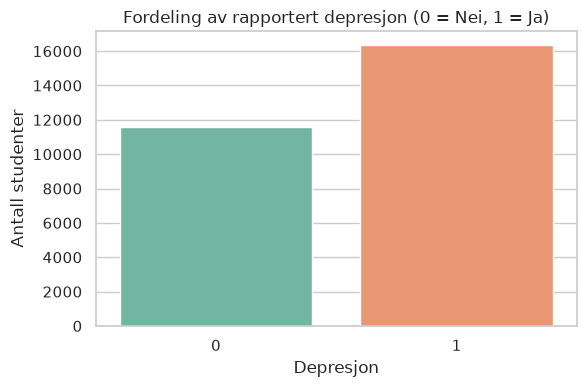

[INFO] Viser og lagret 'figurer/figur2_korrelasjonsmatrise.png'


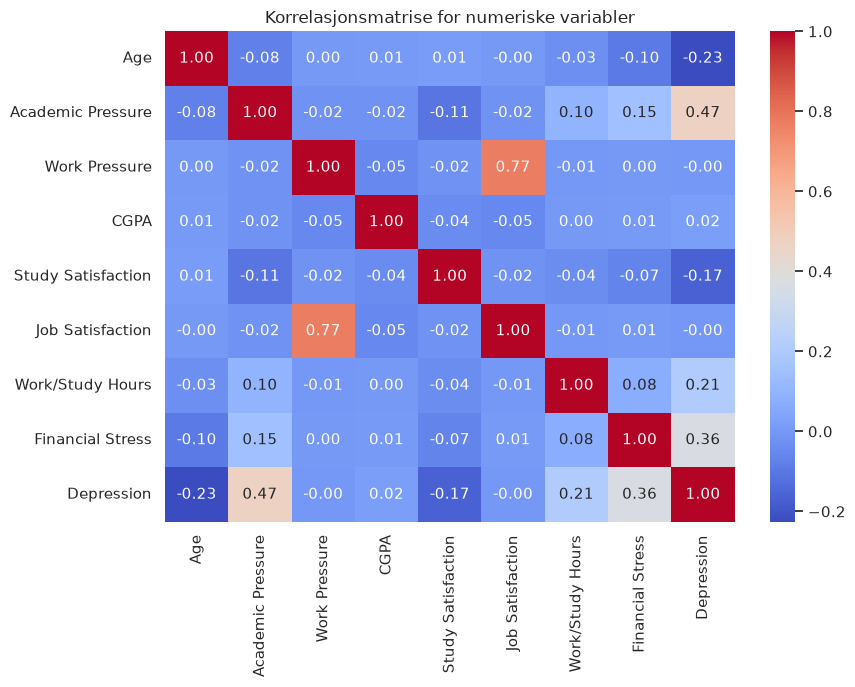


----------------------------------------
3. Multippel Lineær Regresjon (Respons: CGPA)
----------------------------------------
Forklaringsvariabler: ['Work/Study Hours', 'Academic Pressure', 'Financial Stress']
Skjæringspunkt (Intercept): 7.6949
Koeffisient for Work/Study Hours: 0.0017
Koeffisient for Academic Pressure: -0.0256
Koeffisient for Financial Stress: 0.0094
R² (Forklart varians): 0.0006
RMSE: 1.4702

----------------------------------------
4. Klassifikasjon (Respons: Depression)
----------------------------------------
Nøyaktighet (Accuracy): 0.7858
Sensitivitet (Recall for Depresjon=1): 0.8465
Spesifisitet (Recall for Depresjon=0): 0.7001

Forvekslingsmatrise:
[[2024  867]
 [ 627 3457]]
[INFO] Viser og lagret 'figurer/figur3_forvekslingsmatrise.png'


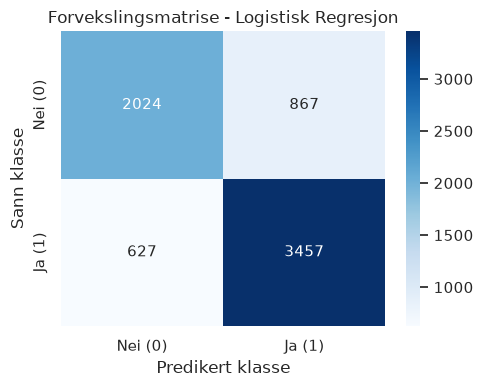


----------------------------------------
5. Klyngeanalyse (K-Means)
----------------------------------------
Fullført k-means klyngeanalyse med k=3.

Størrelse per klynge:
Klynge
0    11226
1     7973
2     8699
Name: count, dtype: int64

Gjennomsnittsverdier per klynge:
            CGPA  Work/Study Hours  Academic Pressure  Financial Stress
Klynge                                                                 
0       7.652373          9.099501           3.871815          4.197844
1       7.675948          2.302019           2.851123          2.985325
2       7.642911          9.098632           2.464651          1.916197

Andel depresjon per klynge:
Klynge
0    0.844201
1    0.425938
2    0.397977
Name: Depression, dtype: float64
[INFO] Viser og lagret 'figurer/figur4_klynger.png'


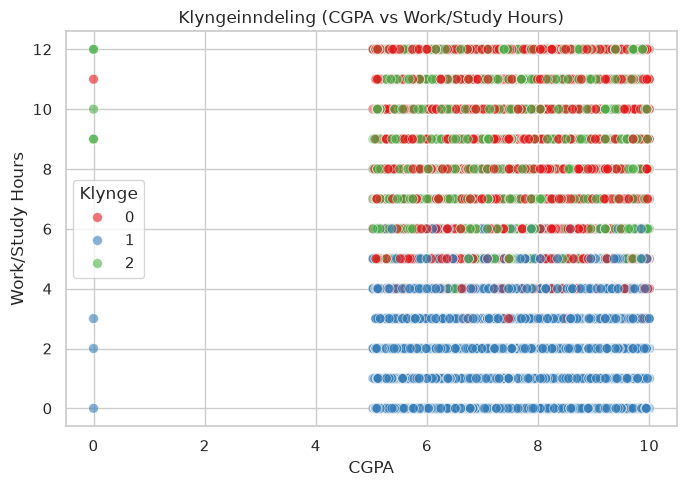


Analysen er fullført! Alle figurer er lagret i mappen '/figurer'.


In [6]:
if __name__ == "__main__":

  kjoer_full_analyse("Student_Depression_Dataset.csv")